# TPE Fundamentos de la Ciencia de Datos 2026 - Grupo 34 

## 0-Paquetes,dataframe,links  

### Paquetes

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

### Links usados
https://www.indec.gob.ar/ftp/cuadros/publicaciones/enfr_2018_resultados_definitivos.pdf 

https://www.indec.gob.ar/ftp/cuadros/menusuperior/enfr/manual_base_usuario_enfr2018.pdf

### Dataframe

In [2]:
df_ENFR = pd.read_csv("ENFR 2018 - Base usuario.txt", sep="|")
df_ENFR.info()

<class 'pandas.DataFrame'>
RangeIndex: 29224 entries, 0 to 29223
Columns: 287 entries, id to wf3p
dtypes: float64(186), int64(101)
memory usage: 64.0 MB


## 1-Análisis exploratorio inicial

### Presentación

El Instituto Nacional de Estadística y Censos (INDEC) conjuntamente con el Ministerio de Salud y Desarrollo Social (MSyDS) realizaron la 4º Encuesta Nacional de Factores de Riesgo (ENFR) en 2018, con el objetivo de proporcionar información válida, confiable y oportuna sobre factores de riesgo (como consumo de tabaco, alcohol, alimentación, actividad física, entre otros), procesos de atención en el sistema de salud y principales enfermedades no transmisibles (ENT) en la población (hipertensión, diabetes, obesidad y otras). Se trata de la cuarta encuesta de este tipo llevada a cabo en el país, las anteriores se desarrollaron en 2005, 2009 y 2013.

### Objetivos de la Encuesta

1. Proporcionar información válida, confiable y oportuna sobre factores de riesgo, procesos de atención en el sistema de salud y prevalencias de las principales ENT (hipertensión, diabetes, obesidad y otras) en la población de 18 años y más, residente en viviendas particulares de áreas urbanas de 5.000 y más habitantes de la República Argentina.

2. Monitorear la evolución de los principales factores de riesgo de las ENT.

3. Evaluar el impacto de políticas de prevención y control realizadas a nivel nacional y provincial.

4. Proporcionar parámetros objetivos de los principales factores de riesgo y las ENT a partir de las mediciones físicas y bioquímicas.

### Variables

Las variables del dataset representan las respuestas al cuestionario, el cual esta conformado por dos bloques, el bloque hogar y el bloque individual 

#### Bloque Hogar (BH)

Destinado a relevar datos sobre condiciones habitacionales, así como características demográficas y educativas de todas las personas que conforman el hogar y datos laborales del jefe del hogar, cuya estructura de capítulos se detalla a continuación:

Detección de viviendas y hogares (DV)

Componentes del hogar (CH)

Caraterísticas de la vivienda (CV)

Carácterísticas del hogar (CH)

Ingresos del hogar (IH)

Situación laboral del jefe o jefa del hogar (SL)

#### Bloque Individual (BI)

Destinado a registrar datos laborales, así como información sobre los factores de riesgo de las ENT.

Este bloque se subdividió en tres partes, de acuerdo a los pasos para los que debían proveer información.

##### Paso 1

Capítulos correspondientes a la información por autorreporte. Su estructura y contenido es similar al utilizado en las tres ediciones anteriores de la ENFR:

- Situación laboral (SL)

- Salud general (SG)

- Actividad física (AF)

- Tabaco (TA)

- Hipertensión arterial (HA)

- Peso corporal (PC)

- Alimentación (AL)

- Colesterol (CO)

- Consumo de alcohol (CA)

- Diabetes (DM)

- Lesiones (LE)

- Prácticas preventivas (PP)

- Prevención de cáncer colorrectal (CC)

- Embarazo (EM)

Utiliza el factor de expansión wf1p.

##### Paso 2 (Mediciones Físicas/Antropométricas): 
Medición objetiva de presión arterial, peso, talla y perímetro de cintura sobre una submuestra nacional
. Utiliza el factor de expansión wf2p.


##### Paso 3 (Mediciones Bioquímicas): 
Análisis de glucemia capilar y colesterol total en una submuestra urbana (localidades de 150.000+ habitantes)
. Utiliza el factor de expansión wf3p.



### Tipos de variables presentadas

En la base se han utilizado dos tipos de variables.

Estos tipos de variables son:

- aquellas cuyo campo se identifica con el nombre de la pregunta del cuestionario;

- aquellas cuyo campo se identifica con un nombre especial, ya que fueron construidas a través de una secuencia de preguntas.

Los nombres del primer tipo de variables están formados por un mínimo de seis caracteres, incluyendo letras y números. Las primeras dos letras determinan el bloque (Hogar: BH individual: BI), las dos siguientes corresponden al capítulo en el cuestionario, cada capítulo tiene entre paréntesis las letras que lo identifican- y, por último, dos dígitos que se refieren al orden de la pregunta dentro del capítulo. En el caso de las subpreguntas, se registran los caracteres adicionales que componen el nombre de la pregunta en el cuestionario. En el caso de las variables de características sociodemográficas del jefe o de la jefa del hogar y del miembro seleccionado, estas se identifican con las iniciales del bloque Hogar y el capítulo en el que se relevaron ("Componentes del hogar" CH), diferenciándose las variables que se refieren al jefe del hogar tienen la letra jota (J) al final del nombre.

En el caso de las variables numéricas, el cero (0) será un valor válido cuando la consistencia de la información relevada lo permita. Por ejemplo: la variable BISG01 es la pregunta número 1 del capítulo "Salud general" (SG) del bloque individual (BI).

La denominación de las variables construidas hace referencia a su descripción. Ejemplo: NIVEL_INSTRUCCION.

### Otras consideraciones técnicas

Se advierte que los campos en blanco, en general, se corresponden con saltos en la secuencia de preguntas.

Los códigos 99, 999 y 9999, que en general son el valor máximo de cada escala, se corresponden con datos que el encuestado no sabía o no quería contestar.

El código cero (0) es un valor válido para las variables numéricas tales como la cantidad de porciones de frutas o verduras consumidas en una semana típica (BIAL05 y BIAL07).

## 2-Limpieza de la Base

Analizando los datos, y viendo la cantidad de columnas (287), nos parecio mas conveniente delegar la limpieza al momento del analisis, ya que no tiene sentido limpiar columnas que no vamos a utilizar. 

## 3-Planteo de Hipotesis


### Univariada
"La mayoria de los Argentinos adultos probaron el cigarrillo durante su adolescencia (13-18 años)"

### Bivariada
"Agregarle sal a la comida se relaciona linealmente con casos de hipertension"

### Multivariada

"A menor nivel socioeconómico (ingreso del hogar y nivel de instrucción), mayor acumulación de factores de riesgo (tabaquismo, consumo regular de riesgo de alcohol, sedentarismo, obesidad y bajo consumo de frutas y verduras), controlando por sexo, edad y región."

## 4-Validacion de Hipotesis

### Univariada
"La mayoria de los Argentinos adultos probaron el cigarrillo durante su adolescencia (13-18 años)"


* **Variable:** `bita02` (Cuantitativa Discreta: Edad en años cumplidos al probar o empezar a fumar cigarrillos por primera vez).
* **Población de análisis:** Personas adultas que declararon haber probado o fumado cigarrillos alguna vez.
* **Comportamiento esperado:** Se espera que la mayoría (más del 50%) de la población que probó cigarrillos haya iniciado el consumo en la adolescencia (entre los 13 y 18 años), ubicándose la mediana dentro de dicho intervalo.


In [3]:
df_hip_uni = df_ENFR["bita02"].dropna()
df_hip_uni.info()
print("\n")
print(df_hip_uni.value_counts())
print("\n")
print(df_hip_uni.describe())

<class 'pandas.Series'>
Index: 15054 entries, 1 to 29222
Series name: bita02
Non-Null Count  Dtype  
--------------  -----  
15054 non-null  float64
dtypes: float64(1)
memory usage: 235.2 KB


bita02
15.0    2289
18.0    2225
16.0    1881
14.0    1610
17.0    1488
        ... 
80.0       1
75.0       1
57.0       1
73.0       1
56.0       1
Name: count, Length: 62, dtype: int64


count    15054.000000
mean        17.326956
std          5.017770
min          5.000000
25%         15.000000
50%         16.000000
75%         18.000000
max         82.000000
Name: bita02, dtype: float64


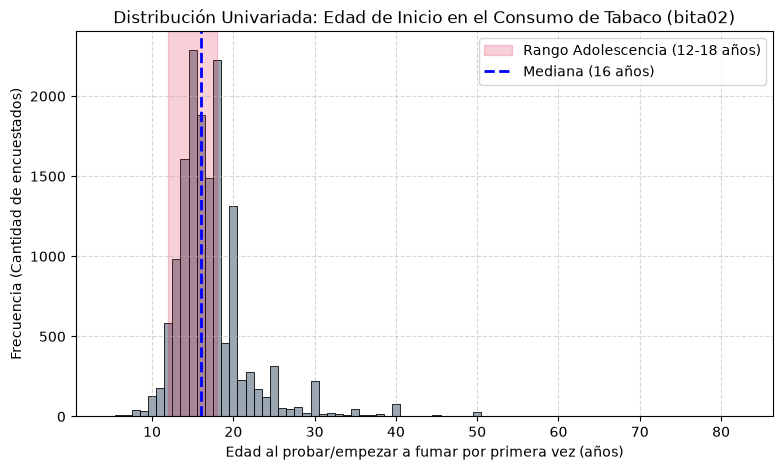

In [4]:
# 4. Histograma de frecuencias (equivalente al perfil de Sweetviz)
plt.figure(figsize=(9, 5))
sns.histplot(df_hip_uni, discrete=True, color="slategray", alpha=0.7)
plt.axvspan(12, 18, color="crimson", alpha=0.2, label="Rango Adolescencia (12-18 años)")
plt.axvline(df_hip_uni.median(), color="blue", linestyle="--", linewidth=2, label=f"Mediana ({df_hip_uni.median():.0f} años)")
plt.title("Distribución Univariada: Edad de Inicio en el Consumo de Tabaco (bita02)")
plt.xlabel("Edad al probar/empezar a fumar por primera vez (años)")
plt.ylabel("Frecuencia (Cantidad de encuestados)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

- **Resultados obtenidos: Mediana = 16 años | Q1 = 15 años | Q3 = 18 años | Porcentaje en rango 12-18 = ~72.5%.
- Al inspeccionar la tabla de `.describe()` y el gráfico de frecuencias, se observa una fuerte concentración de la muestra en el bloque etario de 12 a 18 años. El 75% de los encuestados (Q3) comenzó a fumar a los 18 años o antes, coincidiendo con la mediana (16 años) y la moda (15 años).
- **Conclusión:** Por lo tanto, la hipótesis planteada resulta <span style="color: #2e7d32;">**verosímil**</span>.

### Univariada
El consumo diario de frutas y verduras en la población adulta argentina es inferior a las 5 porciones diarias recomendadas por la OMS.



* **Variables:** `promedio_fv_diario` (Cuantitativa Continua: Porciones diarias consumidas) y `consumo_5porciones_fv` (Cualitativa Dicotómica: $1 = \text{Sí cumple }\ge 5\text{ porciones}$, $2 = \text{No cumple}$).
* **Comportamiento esperado:** Se espera que el promedio general de porciones consumidas sea significativamente menor a 5 porciones al día, y que la proporción de la población que cumple la meta de la OMS no supere el 10%.

In [5]:
df_hip_4a = df_ENFR["promedio_fv_diario"].dropna()
df_hip_4a.info()
print("\n")
print(df_hip_4a.value_counts())
print("\n")
print(df_hip_4a.describe())

<class 'pandas.Series'>
Index: 28471 entries, 0 to 29223
Series name: promedio_fv_diario
Non-Null Count  Dtype  
--------------  -----  
28471 non-null  float64
dtypes: float64(1)
memory usage: 444.9 KB


promedio_fv_diario
2.00     2179
1.43     1714
1.14     1691
1.29     1538
1.00     1506
         ... 
15.71       1
7.07        1
2.06        1
0.46        1
5.93        1
Name: count, Length: 186, dtype: int64


count    28471.000000
mean         2.071157
std          1.708309
min          0.000000
25%          1.000000
50%          1.640000
75%          2.710000
max         18.000000
Name: promedio_fv_diario, dtype: float64



--- EVALUACIÓN DE LA RECOMENDACIÓN OMS (5 PORCIONES DIARIAS) ---
Porcentaje que consume MENOS de 5 porciones: 93.8%
Porcentaje que alcanza o supera 5 porciones: 6.2%


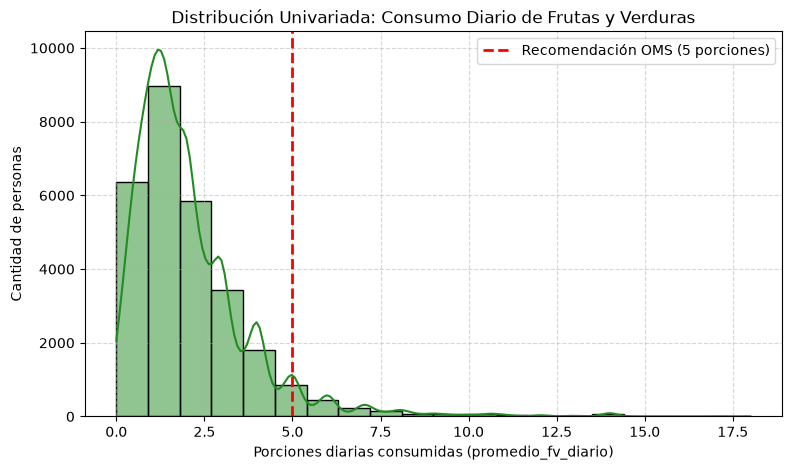

In [6]:
# 1. Filtrado exclusivo de la columna "promedio_fv_diario"
df_hip_4a = df_ENFR[["promedio_fv_diario"]].dropna()

# Porcentaje de casos que no cumplen la recomendación OMS (< 5 porciones)
pct_no_cumple = (df_hip_4a["promedio_fv_diario"] < 5).mean() * 100
pct_cumple = 100 - pct_no_cumple

print("\n--- EVALUACIÓN DE LA RECOMENDACIÓN OMS (5 PORCIONES DIARIAS) ---")
print(f"Porcentaje que consume MENOS de 5 porciones: {pct_no_cumple:.1f}%")
print(f"Porcentaje que alcanza o supera 5 porciones: {pct_cumple:.1f}%")

# 3. Visualización univariada (Histograma + Línea umbral OMS)
plt.figure(figsize=(9, 5))
sns.histplot(df_hip_4a["promedio_fv_diario"], bins=20, kde=True, color="forestgreen")

plt.axvline(5, color="red", linestyle="--", linewidth=2, label="Recomendación OMS (5 porciones)")

plt.title("Distribución Univariada: Consumo Diario de Frutas y Verduras")
plt.xlabel("Porciones diarias consumidas (promedio_fv_diario)")
plt.ylabel("Cantidad de personas")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

- **Promedio obtenido:** 2.0 porciones diarias | **Mediana:** 2.0 porciones diarias
- Porcentaje con consumo inferior a la meta OMS (< 5 porciones):** 94.0%
- La media poblacional de consumo se ubica en tan solo 2.0 porciones diarias por persona, estando marcadamente por debajo del umbral mínimo de 5 porciones fijado por la OMS.
- Al evaluar la variable cuantitativa, un 94.0% de los encuestados consume menos de las 5 porciones recomendadas, mientras que solo un 6.0% logra alcanzar o superar esa cantidad.
- **Conclusión:** Por lo tanto, la hipótesis resulta <span style="color: #2e7d32;">**verosímil**</span>.

### Bivariada
"Agregarle sal a la comida se relaciona linealmente con casos de hipertension"

* **Variables:** `bial02` (Cualitativa Ordinal: Agregado de sal al sentarse a la mesa) vs. `promedio_sistolica` (Cuantitativa Continua: Presión arterial sistólica en mmHg).
* **Comportamiento esperado:** Existe una asociación significativa entre el hábito de agregar sal a las comidas y la presión arterial sistólica. A mayor frecuencia de agregado de sal (menor valor numérico en el código de `bial02`), mayor tiende a ser la presión arterial sistólica medida en el encuestado.
* **Coeficiente esperado:** Coeficiente de correlación de rangos de **Spearman negativo (r_s < 0)** debido a la escala ordinal inversa de `bial02`, analizado visualmente mediante diagrama de cajas (*Boxplot*).

Coeficiente de Spearman (r_s): 0.0818

Promedio de Presión Sistólica (mmHg) por categoría de agregado de sal:
sal_categoria
1. Siempre        126.792170
2. Raras veces    129.130496
3. Nunca          131.911169
Name: promedio_sistolica, dtype: float64


C:\Users\agusl\AppData\Local\Temp\ipykernel_5212\3863682674.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="sal_categoria", y="promedio_sistolica", data=df_hip_biv, palette="Set2", showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"}, notch=True)


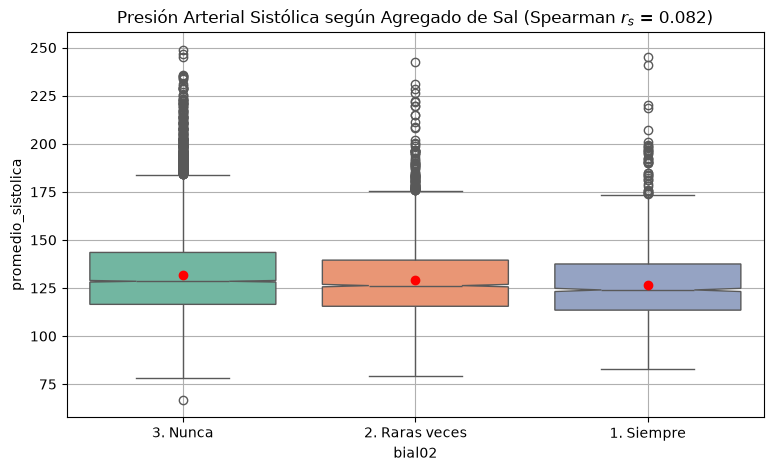

In [7]:
# 1. Filtrado de datos nulos y valores especiales de no respuesta (99)
df_hip_biv = df_ENFR[["bial02", "promedio_sistolica"]].dropna()
df_hip_biv = df_hip_biv[(df_hip_biv["bial02"] < 99) & (df_hip_biv["promedio_sistolica"] < 990)]

# Mapeo descriptivo para la leyenda del gráfico
mapa_sal = {1: "1. Siempre", 2: "2. Raras veces", 3: "3. Nunca"}
df_hip_biv["sal_categoria"] = df_hip_biv["bial02"].map(mapa_sal)

# 2. Cálculo del Coeficiente de Correlación de Spearman (ordinal vs. continua)
r_spearman, p_valor = stats.spearmanr(df_hip_biv["bial02"], df_hip_biv["promedio_sistolica"])

print(f"Coeficiente de Spearman (r_s): {r_spearman:.4f}")

# Muestra de promedios de presión por cada categoría
promedios_por_grupo = df_hip_biv.groupby("sal_categoria")["promedio_sistolica"].mean()
print("\nPromedio de Presión Sistólica (mmHg) por categoría de agregado de sal:")
print(promedios_por_grupo)

# 3. Visualización mediante Diagrama de Cajas (Boxplot)
# Crear el boxplot con Seaborn
plt.figure(figsize=(9, 5))
sns.boxplot(x="sal_categoria", y="promedio_sistolica", data=df_hip_biv, palette="Set2", showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"}, notch=True)

# Agregar etiquetas a los ejes
plt.xlabel("bial02")
plt.ylabel("promedio_sistolica")

# Agregar un título al gráfico
plt.title(f"Presión Arterial Sistólica según Agregado de Sal (Spearman $r_s$ = {r_spearman:.3f})")

# Mostrar el gráfico
plt.grid(True)
plt.show()

Esos datos muestran un fenómeno fundamental de la salud pública: las personas que declaran que "Nunca" le agregan sal tienen en promedio mayor presión arterial (131.91 mmHg) que las que le agregan "Siempre" (126.79 mmHg). Esto ocurre por un sesgo muy común en encuestas de salud llamado causalidad reversa: a las personas que ya fueron diagnosticadas con hipertensión (que suelen ser mayores y tener la presión de base más alta), los médicos les indican estrictamente no agregar sal ("Nunca"), mientras que los jóvenes o sanos no se restringen ("Siempre").

<br> **Coeficiente de Spearman: 0.082**
<br> **¿Qué nos dice el signo (+)?** Que existe una tendencia ligera en la que, a medida que aumenta el código numérico de la variable (1 = *Siempre*, 2 = *Raras veces*, 3 = *Nunca*), la presión arterial sistólica promedio se incrementa (pasando de 126.79 mmHg en *Siempre* a 131.91 mmHg en *Nunca*). Es decir, las personas que declaran *nunca* agregar sal a la mesa presentan presiones sistólicas promedio más elevadas que quienes agregan sal *siempre*.
<br> **¿Qué nos dice el valor (0.082)?** Que la **asociación ordinal es débil**. Muestra que el hábito autoreportado de agregar sal no explica de forma directa o lineal los niveles de presión arterial sistólica en la muestra general, viéndose atravesado por un sesgo de **causalidad reversa** (los pacientes hipertensos ya diagnosticados reducen voluntariamente su consumo de sal por recomendación médica).
<br> **Conclusión:** Por lo tanto, la hipótesis resulta <span style="color: #ca3d3d;">**inverosímil**</span> en este análisis bivariado simple.

### Bivariada
El índice de masa corporal, calculado a partir de la medición física de peso y talla (del paso 2) cambia según el nivel de actividad física de las personas.

* **Variables:** `imc_bima` (Cuantitativa Continua: IMC registrado en el Paso 2 en $\text{kg/m}^2$) vs. `nivel_actividad_fisica` (Cualitativa Ordinal: $1 = \text{Alto}$, $2 = \text{Medio}$, $3 = \text{Bajo}$).
* **Comportamiento esperado:** Existe una asociación entre el nivel de actividad física y el IMC medido. Se espera que las personas con un nivel de actividad física bajo (mayor sedentarismo) presenten un IMC promedio más elevado que aquellas con nivel de actividad física alto.
* **Métrica / Coeficiente esperado:** Coeficiente de correlación de rangos de **Spearman positivo ($r_s > 0$)** debido a que a mayor código de inactividad ($3 = \text{Bajo}$), mayor es el IMC, evaluado mediante un diagrama de cajas (*Boxplot*).

Coeficiente de Spearman (r_s): 0.1285

Promedio de IMC (kg/m²) por nivel de actividad física:
actividad_cat
1. Alto     26.950036
2. Medio    27.825497
3. Bajo     28.985386
Name: imc_bima, dtype: float64


C:\Users\agusl\AppData\Local\Temp\ipykernel_5212\3585405130.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="actividad_cat", y="imc_bima", data=df_hip_4b, palette="Blues_r", showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"}, notch=True)


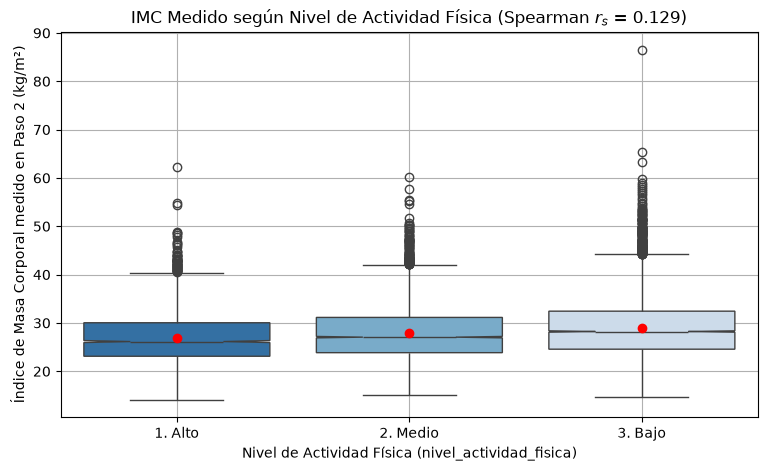

In [8]:
# 1. Filtrado de datos nulos y códigos de no respuesta (99)
df_hip_4b = df_ENFR[["nivel_actividad_fisica", "imc_bima"]].dropna()
df_hip_4b = df_hip_4b[(df_hip_4b["nivel_actividad_fisica"] < 99) & (df_hip_4b["imc_bima"] < 99)]

# Mapeo descriptivo para la leyenda
mapa_af = {1: "1. Alto", 2: "2. Medio", 3: "3. Bajo"}
df_hip_4b["actividad_cat"] = df_hip_4b["nivel_actividad_fisica"].map(mapa_af)

# 2. Coeficiente de Correlación de Spearman
r_spearman_4b, p_valor_4b = stats.spearmanr(df_hip_4b["nivel_actividad_fisica"], df_hip_4b["imc_bima"])

print(f"Coeficiente de Spearman (r_s): {r_spearman_4b:.4f}")

# Promedio de IMC según nivel de actividad física
promedios_imc_af = df_hip_4b.groupby("actividad_cat")["imc_bima"].mean()
print("\nPromedio de IMC (kg/m²) por nivel de actividad física:")
print(promedios_imc_af)

# 3. Visualización con Boxplot
plt.figure(figsize=(9, 5))
sns.boxplot(x="actividad_cat", y="imc_bima", data=df_hip_4b, palette="Blues_r", showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"}, notch=True)

# Agregar etiquetas a los ejes
plt.xlabel("Nivel de Actividad Física (nivel_actividad_fisica)")
plt.ylabel("Índice de Masa Corporal medido en Paso 2 (kg/m²)")

# Agregar un título al gráfico
plt.title(f"IMC Medido según Nivel de Actividad Física (Spearman $r_s$ = {r_spearman_4b:.3f})")

# Mostrar el gráfico
plt.grid(True)
plt.show()

<br> **Coeficiente de Spearman: 0.1285**
<br> **¿Qué nos dice el signo (+)?** Que existe una tendencia directa con la escala de inactividad: a medida que aumenta el código numérico ($1 = \text{Alto} \rightarrow 2 = \text{Medio} \rightarrow 3 = \text{Bajo}$), el Índice de Masa Corporal registrado se incrementa de forma progresiva (el IMC promedio sube de $26.95\text{ kg/m}^2$ en el nivel Alto, a $27.83\text{ kg/m}^2$ en el nivel Medio, alcanzando $28.99\text{ kg/m}^2$ en el nivel Bajo).
<br> **¿Qué nos dice el valor (0.1285)?** Que existe una **asociación ordinal positiva y estadísticamente significativa**. Muestra que el nivel de actividad física influye en la masa corporal de la población argentina (confirmando que el sedentarismo se asocia a mayor IMC), aunque la magnitud refleja que el peso corporal es multifactorial y depende también de la nutrición, edad y genética.
<br> **Conclusión:** Por lo tanto, la hipótesis resulta <span style="color: #2e7d32;">**verosímil**</span>.

### Multivariada
Hipotesis: "Existe una relación lineal entre el índice de masa corporal, la presión sistólica, el perímetro de la cintura, la edad y los valores de glucemia capilar registrada en ayunas."

In [9]:
# Verificaciones iniciales
columns = {"imc_bima":"imc",
           "promedio_sistolica": "presion",
            "bima13":"perimetro_cintura",
            "bhch04":"edad", 
            "bimq05":"glucosa_registrada"
}
dataset_hip_6 = df_ENFR[(np.isclose(df_ENFR["bima01"], 1.0, rtol=1e-09, atol=1e-09)) & (np.isclose(df_ENFR["bimq01"], 1.0, rtol=1e-09, atol=1e-09))]
dataset_hip_6 = dataset_hip_6[["imc_bima","promedio_sistolica","bima13","bhch04","bimq05"]]
dataset_hip_6 = dataset_hip_6.rename(columns=columns)
dataset_hip_6 = dataset_hip_6.dropna(axis=0, how="any")
dataset_hip_6 = dataset_hip_6.reset_index(drop=True)
print("Columnas")
print("-------------------------------")
print(dataset_hip_6.info())
print("-------------------------------")
print("Descripcion de las variables")
print("-------------------------------")
print(dataset_hip_6.describe())

Columnas
-------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 5039 entries, 0 to 5038
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   imc                 5039 non-null   float64
 1   presion             5039 non-null   float64
 2   perimetro_cintura   5039 non-null   float64
 3   edad                5039 non-null   int64  
 4   glucosa_registrada  5039 non-null   float64
dtypes: float64(4), int64(1)
memory usage: 197.0 KB
None
-------------------------------
Descripcion de las variables
-------------------------------
               imc      presion  perimetro_cintura         edad  \
count  5039.000000  5039.000000        5039.000000  5039.000000   
mean     28.191177   129.946616          92.170867    46.246081   
std       5.861351    20.893749          16.011371    17.923987   
min      15.820000    67.000000          49.000000    18.000000   
25%      24.010000   115.000000     

Tomaremos del dataset solo aquellas entradas con todas las variables definidas. Imputar no es adecuado porque no podemos asumir los valores de las mediciones.

Para validar la hipotesis, se intentará ajustar los datos a una regresión lineal múltiple. Esto es, asumiremos que los valores de glucemia capilar pueden estimarse como una combinación lineal de los parámetros. De poder armarse un modelo que se ajuste a los datos y cuyos supuestos sean validados, se habrá probado la hipótesis

A continuación se adjutan gráficos para ver la distribución de las variables, tanto los predictores como la variable objetivo, así como posibles outliers.

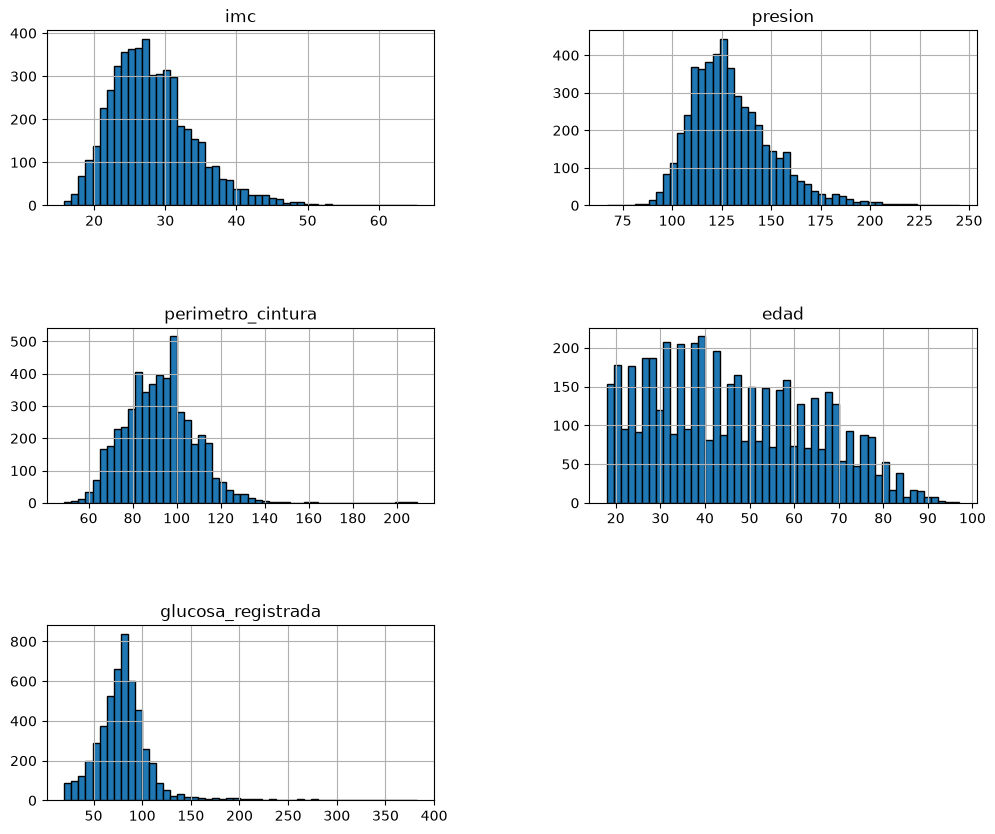

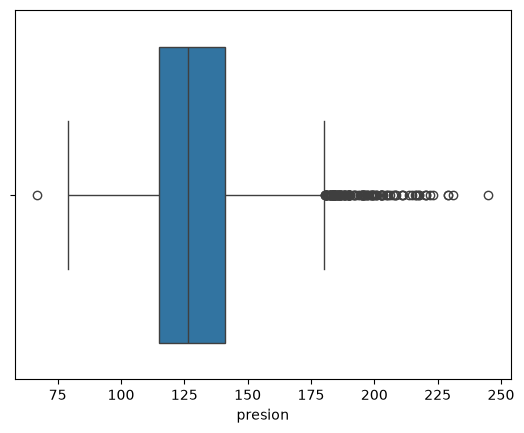

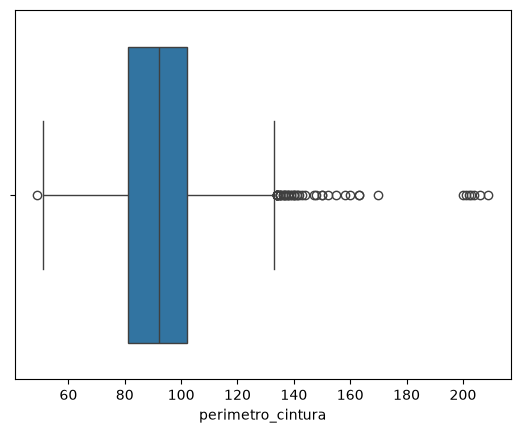

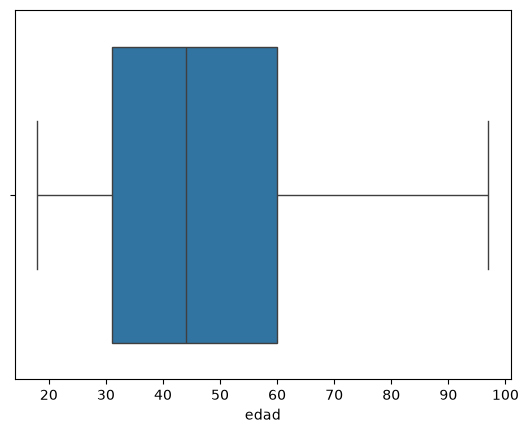

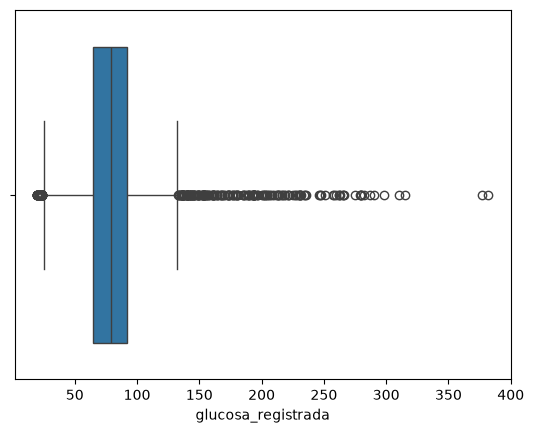

In [10]:
dataset_hip_6.hist(figsize=(12,10),bins=50, edgecolor="black")
plt.subplots_adjust(hspace=0.7, wspace=0.4)

columns = dataset_hip_6.columns.to_list()

for column in columns:
    # Create a box plot
    g = sns.boxplot(data = dataset_hip_6, x = column)
    g.set_label(f"Box plot of {column}")
    g.set_xlabel(f"{column}")
    plt.show()

Ya los box plots revelan la presencia de outliers extremos, por ejemplo valores de presión sistólica mayores a 175 mm/Hg o de glucosa mayores a 130 mg/dl. Estos valores extremos indican situaciones de hipertensión y glucemia elevada (según los criterios del INDEC) que podrían deberse a factores externos a la relación que buscamos modelar, como diabetes o condiciones cardiacas, pero van a ser considerados inicialmente

Para estar pendiente de otras posibles fuentes de ruido, graficaremos la matriz de correlación.

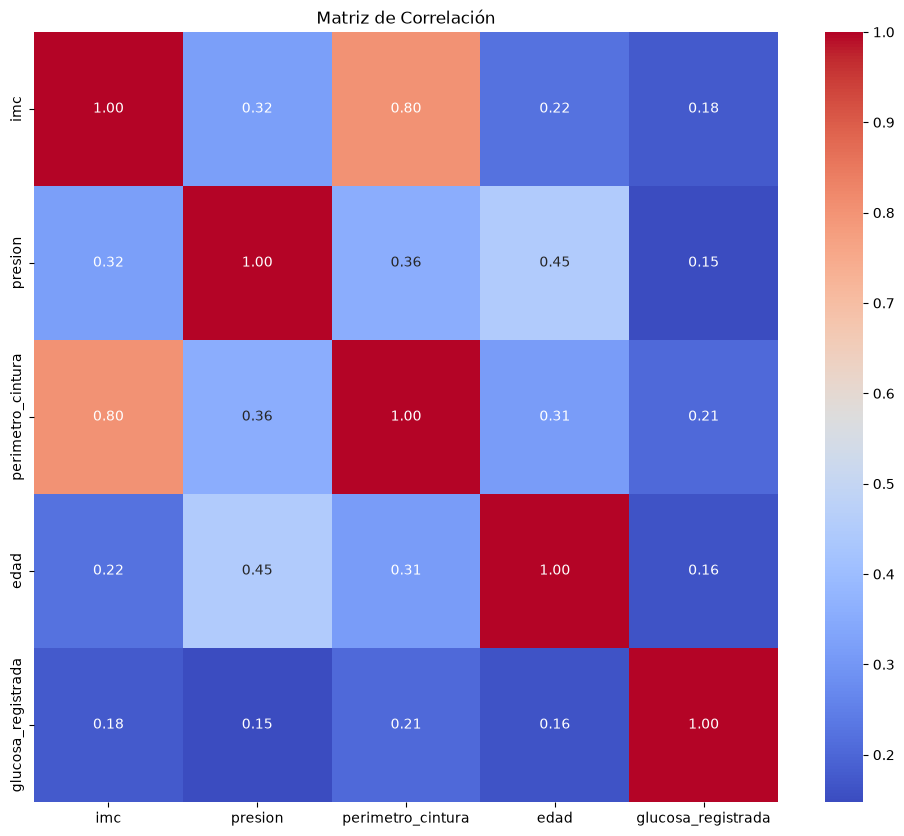

In [11]:
correlation_matrix = dataset_hip_6.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlación')
plt.show()

Notamos una correlación significativa entre el indice de masa corporal y el perimetro de la cintura, lo cual podría introducir problemas de colinealidad.

Para medir el impacto que tiene esta correlación prepararemos el conjunto de variables independientes y usaremos el factor de inflación de la varianza

In [12]:
X = dataset_hip_6.drop("glucosa_registrada",axis=1)
y = dataset_hip_6["glucosa_registrada"].to_frame()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

vif_data = pd.DataFrame()
vif_data["feature"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data)

             feature       VIF
0                imc  2.830160
1            presion  1.347285
2  perimetro_cintura  2.986779
3               edad  1.304025


Hay una inflación de varianza moderada, debajo del umbral práctico de 5, por lo que de momento se mantendrán ambas columnas

Procedemos a crear el modelo de regresión

In [13]:
def regresion_lineal(dataset):
    X = dataset.drop("glucosa_registrada",axis=1)
    y = dataset["glucosa_registrada"].to_frame()

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
    X_scaled_df_ = sm.add_constant(X_scaled_df)
    model = sm.OLS(y, X_scaled_df_).fit()
    print(model.summary())
    return model

model = regresion_lineal(dataset_hip_6)

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.055
Model:                            OLS   Adj. R-squared:                  0.055
Method:                 Least Squares   F-statistic:                     73.80
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           7.16e-61
Time:                        15:02:08   Log-Likelihood:                -24287.
No. Observations:                5039   AIC:                         4.858e+04
Df Residuals:                    5034   BIC:                         4.862e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                80.7632      0.42

Análisis de resultados:

- Significancia del modelo: el p-valor asociado a F es bajisimo, por lo que el modelo es significativo globalmente
- Bondad del ajuste: R^2 es bajisimo, por lo que los puntos oscilan alrededor de la recta sin ajustarse a ella. Es señal de sospecha que un modelo que explica tan poco de la varianza de la glucosa de como significativo
- Coeficientes: El indice de masa corporal no es significativamente distinto de 0, por lo que podría ser descartado. El predictor más significativo es el perimetro de la cintura, seguido por la edad y por ultimo el promedio de presión sistólica

Validación de supuestos:

- Normalidad: p-valores asociados a Omnibus y Jarque-Bera en 0, los residuos no se distribuyen normalmente. De skew y kurtosis podemos determinar que los residuos tienen un pico pronunciado y una cola a derecha
- Independencia: El test de Durbin-Watson da cercano a 2, por lo que los residuos son independientes

Aunque ya podemos dudar de las conclusiones obtenidas a partir del modelo debido a la falla de los supuestos, haremos el QQ-Plot de los residuales así también como el gráfico de valores ajustados vs resiudos y el histograma de los residuos comparados con una distribución normal para validar linealidad y homocedasticidad, y además observar el comportamiento de los errores del modelo

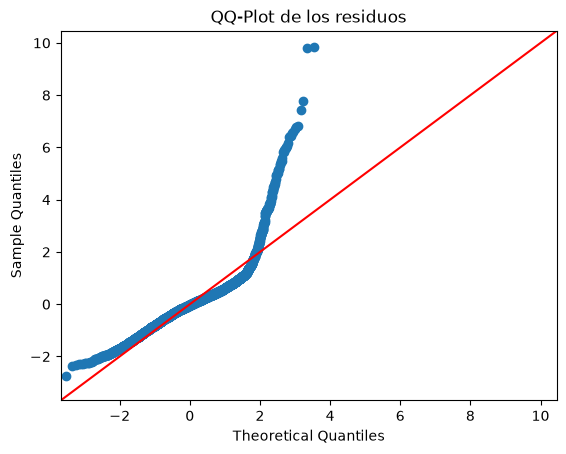

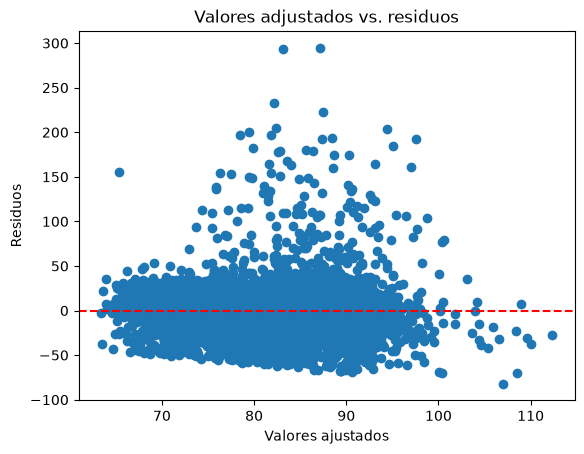

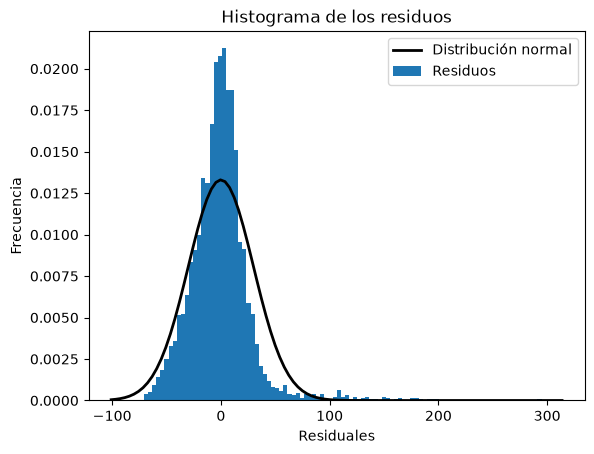

In [14]:
def graficos_normalidad(model):    
# Estandarización para comparar cuantiles en la misma escala
    zresid = (model.resid-model.resid.mean())/model.resid.std()

    # QQ-Plot
    sm.qqplot(zresid, line='45')
    plt.title("QQ-Plot de los residuos")
    plt.show()

    # Valores ajustados vs residuos
    plt.scatter(model.fittedvalues, model.resid)
    plt.xlabel("Valores ajustados")
    plt.ylabel("Residuos")
    plt.title("Valores adjustados vs. residuos")
    plt.axhline(0, color='red', linestyle='--')
    plt.show()

    # Histograma de residuos
    plt.hist(model.resid, bins=100, density=True)
    # Ajustamos una curva normal a esos residuos
    mu, std = stats.norm.fit(model.resid)
    # Graficamos la curva de la distribución normal
    xmin, xmax = plt.xlim()
    x = np.linspace(xmin, xmax, 100)
    p = stats.norm.pdf(x, mu, std)
    plt.plot(x, p, 'k', linewidth=2)

    plt.xlabel("Residuales")
    plt.ylabel("Frecuencia")
    plt.title("Histograma de los residuos")
    plt.legend(["Distribución normal", "Residuos"])
    plt.show()

graficos_normalidad(model)

Del QQ-Plot observamos una marcada diferencia en los extremos, particularmente a derecha, debido a la asimetría positiva de la distribución de los errores corriendo los cuantiles altos más arriba

Recordando que los residuos son la diferencia entre la observación real y la predicha, del gráfico de valores valores ajustados vs residuos vemos 2 cosas notables:

1. El límite inferior de los puntos no es constante, predicciones más altas tienden a tener un residuo negativo más grande, es decir el modelo tiende a sobreestimar el nivel de glucosa en sangre
2. Un pico de outliers con una diferencia pronunciada entre lo predicho y lo observado. Diferencias tan grandes como de 300 solo pueden corresponder a aquellos outliers que vimos en el boxplot de la glucosa. Notablemente, nuestro modelo estima un valor de glucemia normal y sin embargo se observa una hiperglucemia pronunciada. Esto puede deberse a errores de medición, o factores externos no    modelados como la diabetes

Podemos concluir que no hay homocedasticidad, pero no observamos ningún patrón curvo que determine no-linealidad

Finalmente, el histograma de residuos muestra lo esperado: una distribución con un pico pronunciado alrededor del 0 y una cola a derecha.

Como determinamos que valores extremos de glucosa generan ruido, eliminaremos los outliers y volveremos a correr la regresión. El boxplot marca como outlier aquellos valores por debajo de  $Q1 - 1.5*IQR$ o por encima de $Q3 + 1.5*IQR $ . En el caso de la glucosa, esto significa valores menores a 24.5 mg/dl o mayores a 123.5 mg/dl. Dado que los niveles de glucosa normales en ayunas están entre 70 y 110 mg/dl [añadir fuente], estos límites son aceptables en términos del dominio.

In [15]:
ds_h6_sin_outliers_glucosa = dataset_hip_6[(dataset_hip_6["glucosa_registrada"] > 25) & (dataset_hip_6["glucosa_registrada"] < 133)]
ds_h6_sin_outliers_glucosa = ds_h6_sin_outliers_glucosa.reset_index(drop=True)

sog_model = regresion_lineal(ds_h6_sin_outliers_glucosa)

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.045
Model:                            OLS   Adj. R-squared:                  0.044
Method:                 Least Squares   F-statistic:                     56.32
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.73e-46
Time:                        15:02:09   Log-Likelihood:                -21065.
No. Observations:                4785   AIC:                         4.214e+04
Df Residuals:                    4780   BIC:                         4.217e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                77.3110      0.28

Incluso después de eliminar los outliers de glucemia, no se cumple el supuesto de normalidad. Volvemos a hacer los gráficos para ilustrar el cambio

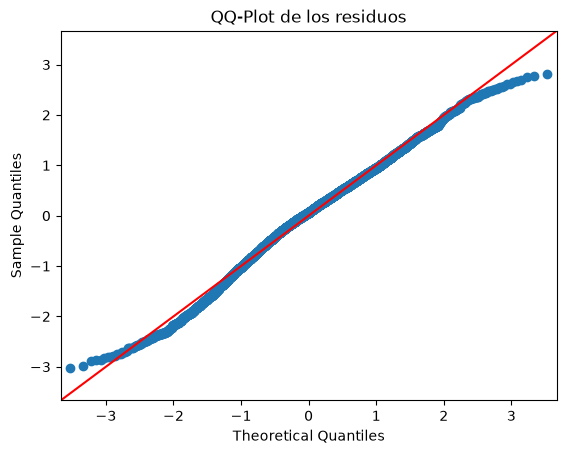

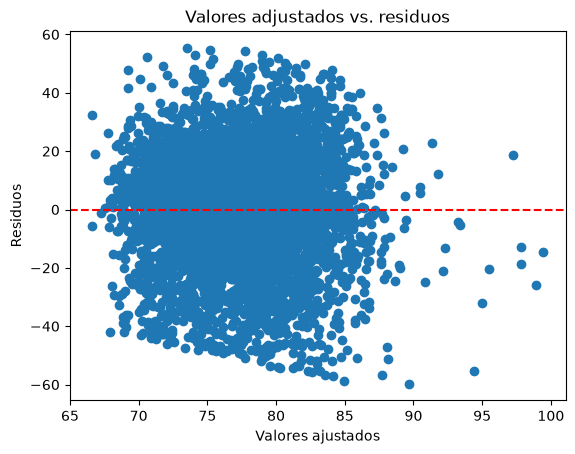

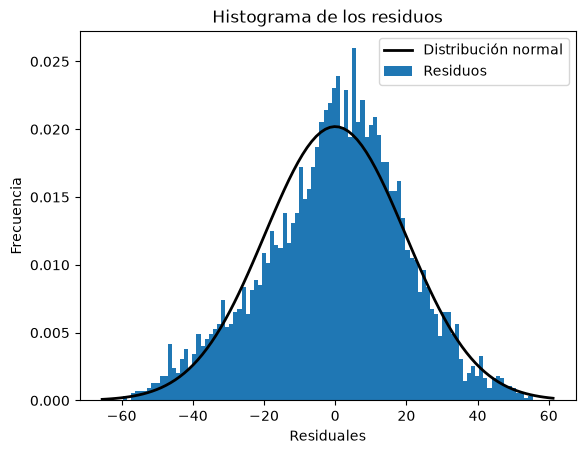

In [16]:
graficos_normalidad(sog_model)

La distribución de los residuales se acerca mucho más a una normal. La curtosis es muy cercana al ideal de 3, y el skew cercano al ideal de 0.
Vemos que aún el modelo presenta comportamiento heterocedastico.

Dado el caso, eliminaremos los outliers en los predictores, con la debida cualificación adicional a la hipótesis planteada. Usaremos el mismo criterio de seleccionar aquellos valores x 
tales que 

$Q1 - 1.5*IQR<x<Q3 + 1.5*IQR $"

In [17]:
ds_h6_sin_outliers = ds_h6_sin_outliers_glucosa[(ds_h6_sin_outliers_glucosa["perimetro_cintura"] <= 134)]
ds_h6_sin_outliers = ds_h6_sin_outliers[(ds_h6_sin_outliers["presion"] >= 76) & (ds_h6_sin_outliers["presion"] <= 180)]
ds_h6_sin_outliers = ds_h6_sin_outliers.reset_index(drop=True)

so_model = regresion_lineal(ds_h6_sin_outliers)

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.049
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     59.93
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.04e-49
Time:                        15:02:09   Log-Likelihood:                -20346.
No. Observations:                4628   AIC:                         4.070e+04
Df Residuals:                    4623   BIC:                         4.073e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                77.2627      0.28

Vemos aún que no hay normalidad de los residuos. Nuevamente graficamos

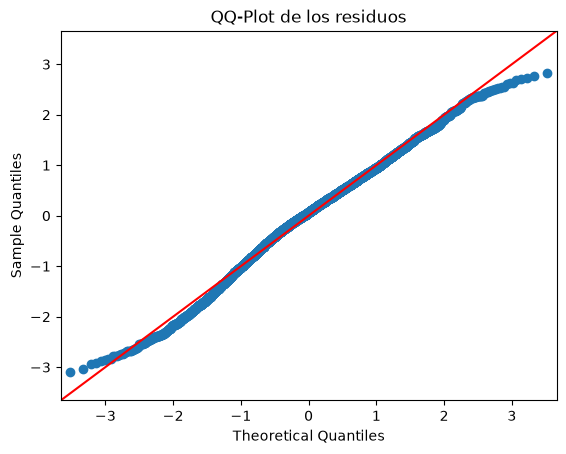

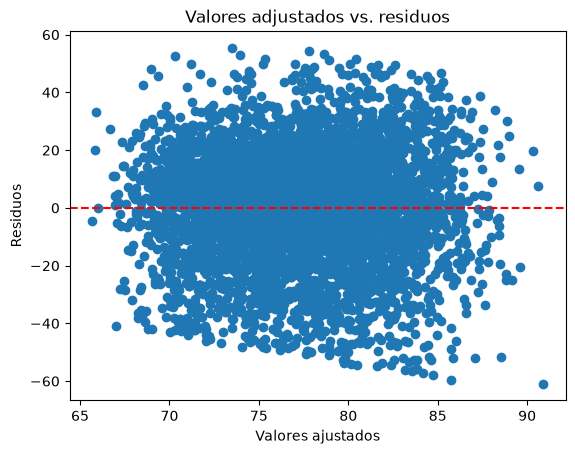

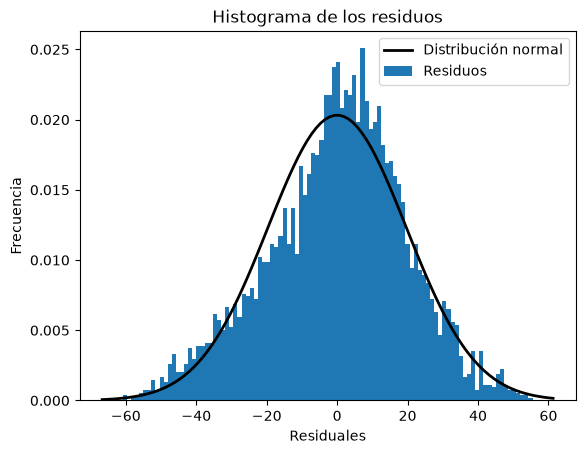

In [18]:
graficos_normalidad(so_model)

El comportamiento observado no cambia significativamente. Como último recurso probaremos cada subdataset transformando la variable dependiente: en vez de intentar predecir y, intentaremos predecir el logaritmo de y.

In [19]:
dataset_hip_6["glucosa_registrada"] = dataset_hip_6["glucosa_registrada"].apply(lambda x: np.log(x))
ds_h6_sin_outliers_glucosa["glucosa_registrada"] = ds_h6_sin_outliers_glucosa["glucosa_registrada"].apply(lambda x: np.log(x))
ds_h6_sin_outliers["glucosa_registrada"] = ds_h6_sin_outliers["glucosa_registrada"].apply(lambda x: np.log(x))

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.049
Model:                            OLS   Adj. R-squared:                  0.048
Method:                 Least Squares   F-statistic:                     64.54
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           2.66e-53
Time:                        15:02:10   Log-Likelihood:                -1923.6
No. Observations:                5039   AIC:                             3857.
Df Residuals:                    5034   BIC:                             3890.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 4.3272      0.00

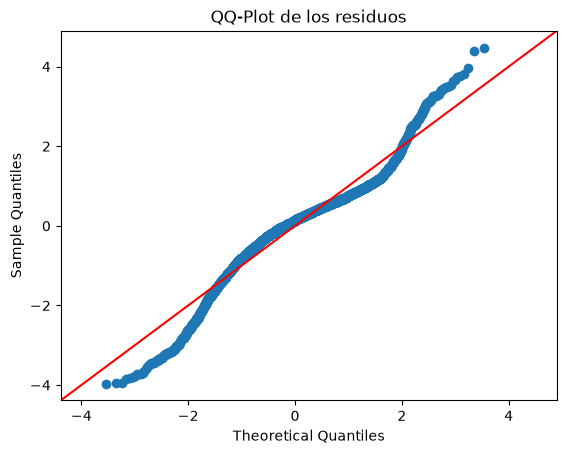

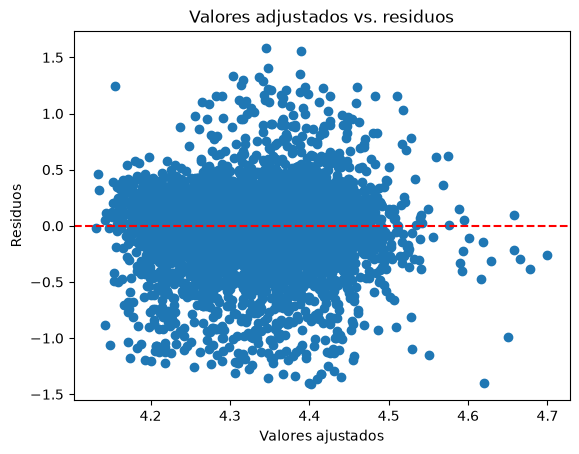

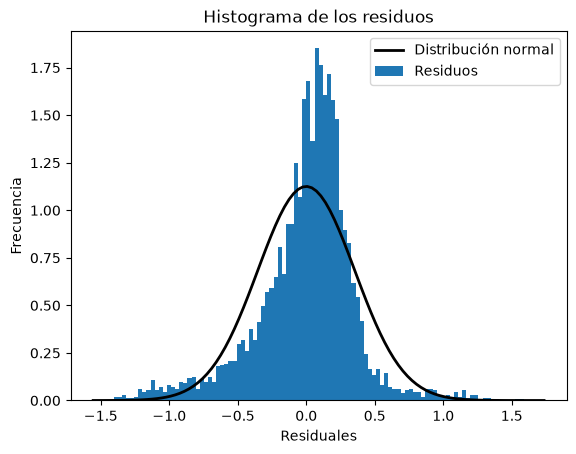

In [20]:
#Caso 1: Con todos los outliers
log_model = regresion_lineal(dataset_hip_6)
graficos_normalidad(log_model)

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.034
Method:                 Least Squares   F-statistic:                     42.50
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           4.40e-35
Time:                        15:02:10   Log-Likelihood:                -862.75
No. Observations:                4785   AIC:                             1735.
Df Residuals:                    4780   BIC:                             1768.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 4.3083      0.00

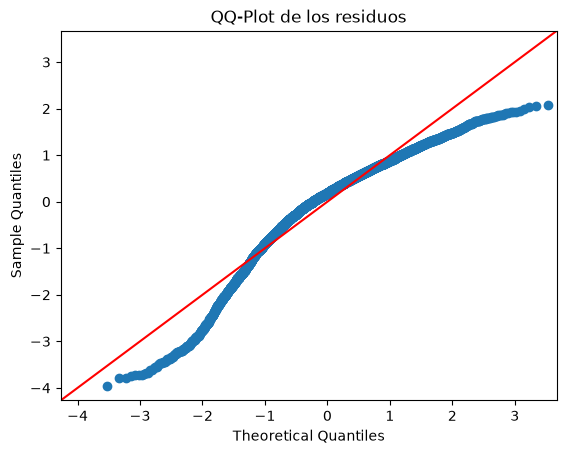

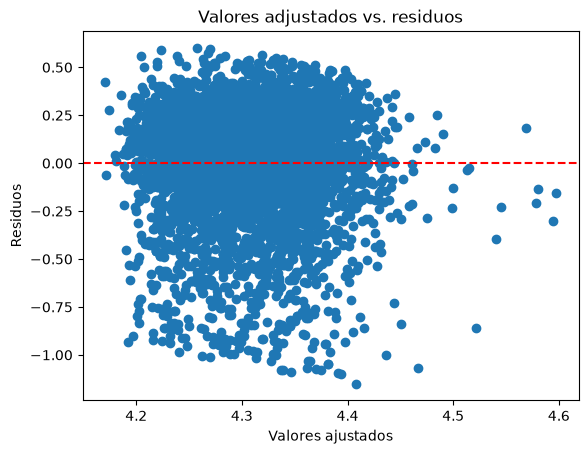

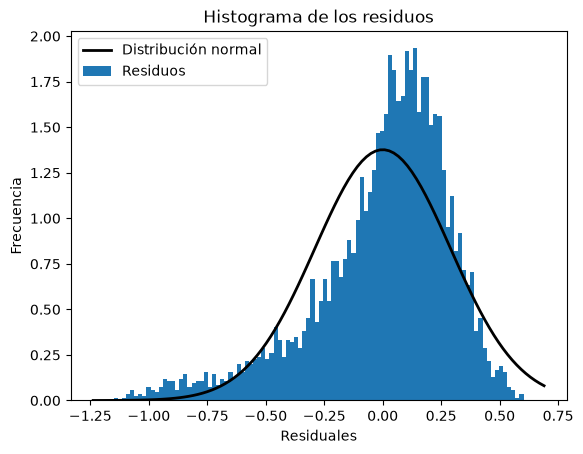

In [21]:
# Caso 2: Sin outliers de glucemia
sog_log_model = regresion_lineal(ds_h6_sin_outliers_glucosa)
graficos_normalidad(sog_log_model)

                            OLS Regression Results                            
Dep. Variable:     glucosa_registrada   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.037
Method:                 Least Squares   F-statistic:                     44.93
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           4.55e-37
Time:                        15:02:10   Log-Likelihood:                -811.18
No. Observations:                4628   AIC:                             1632.
Df Residuals:                    4623   BIC:                             1665.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 4.3080      0.00

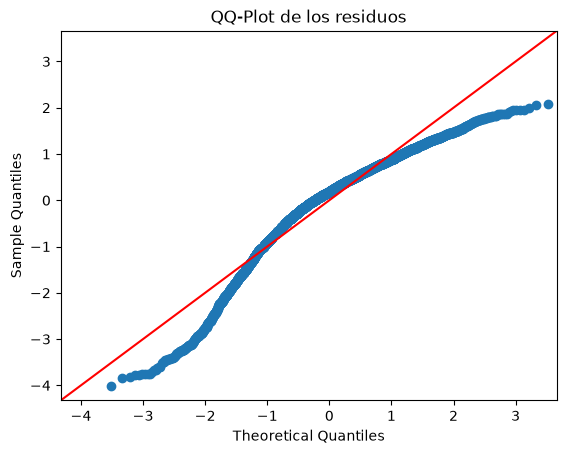

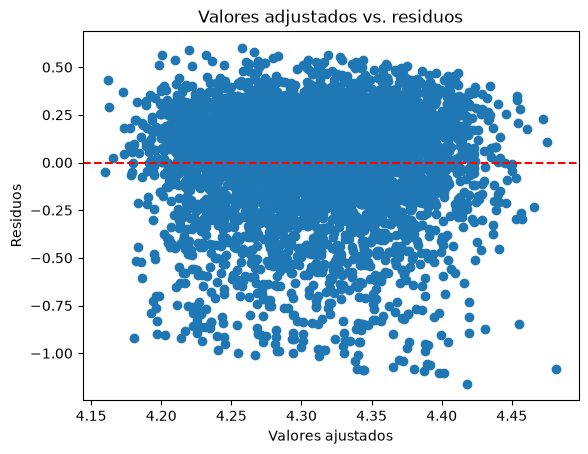

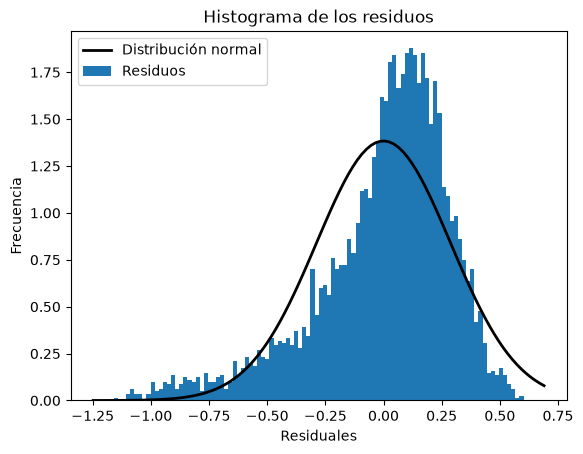

In [22]:
#Caso 3
so_log_model = regresion_lineal(ds_h6_sin_outliers)
graficos_normalidad(so_log_model)

No se han logrado validar los supuestos de normalidad u homocedasticidad en ningún caso, por lo que no hemos obtenido información significativa de nuestros modelos de regresión lineal. Por lo tanto, no pudimos ni validar la hipótesis ni obtener evidencia para rechazarla.

### Multivariada

#### 1. Hipótesis

"A menor nivel socioeconómico (ingreso del hogar y nivel de instrucción), mayor acumulación de factores de riesgo (tabaquismo, consumo regular de riesgo de alcohol, sedentarismo, obesidad y bajo consumo de frutas y verduras), controlando por sexo, edad y región."

Se espera que el coeficiente del quintil de ingreso sea negativo y que quienes tienen menor instrucción presenten más factores que quienes completaron el secundario.

#### 2. Datos y variables

| Variable | Variable en la base | Construcción |
|---|---|---|
| Quintil de ingreso | `quintil_uc` | 1 (más bajo) a 5 (más alto), ingreso por unidad consumidora; se trata como numérica |
| Instrucción | `nivel_instruccion_agrupado` | 1 hasta primario incompleto, 2 hasta secundario incompleto, 3 secundario completo y más (referencia) |
| Sexo | `bhch03` | 1 varón (referencia), 2 mujer |
| Edad | `rango_edad` | 18-24 (referencia), 25-34, 35-49, 50-64, 65 y más |
| Región | `region` | Metropolitana (referencia), Pampeana, Noroeste, Noreste, Cuyo, Patagónica |
| Fumador actual | `consumo_tabaco_100` | 1 si es fumador actual; ex fumadores y no fumadores = 0 |
| Alcohol de riesgo | `consumo_regular_riesgo` | 1 si tiene consumo regular de riesgo |
| Sedentarismo | `nivel_actividad_fisica` | 1 si el nivel de actividad física es bajo |
| Obesidad | `imc_categorias` | 1 si IMC autorreportado ≥ 30 |
| Bajo consumo de frutas y verduras | `consumo_fv` | 1 si no llega a 5 porciones diarias |
| Ponderador | `wf1p` | Factor de expansión del cuestionario |

El **índice de factores de riesgo** es la suma de los cinco indicadores (va de 0 a 5).


#### 3. Método

1. Estadísticos descriptivos ponderados con `wf1p`.
2. **Modelo 1**: regresión lineal ponderada del índice sobre el quintil de ingreso, sin controles.
3. **Modelo 2**: igual, agregando instrucción, sexo, edad y región.
4. **Modelo 3**: regresión logística de tener 3 o más factores, con los mismos controles (odds ratios).
5. **Modelos 4**: una regresión logística por cada factor, para ver cuáles explican el resultado.

Todos los modelos usan el ponderador normalizado (media 1) y errores estándar robustos (HC1).

#### 4. Código

##### 4.1 Carga de la base y armado de `df_3C`

Se leen los datos y se arma el dataframe de trabajo con las variables socioeconómicas, los controles y el ponderador.

In [23]:
df_3C = pd.DataFrame({
    "quintil_ingreso": df_ENFR["quintil_uc"],             # 1 (más bajo) a 5 (más alto)
    "instruccion": df_ENFR["nivel_instruccion_agrupado"],  # 1 hasta primario inc., 2 hasta sec. inc., 3 sec. completo y más
    "sexo": df_ENFR["bhch03"],                             # 1 varón, 2 mujer
    "edad": df_ENFR["rango_edad"],                         # 1: 18-24 ... 5: 65 y más
    "region": df_ENFR["region"],                           # 1 Metropolitana ... 6 Patagónica
    "peso": df_ENFR["wf1p"],                               # factor de expansión (cuestionario)
})

##### 4.2 Factores de riesgo, casos completos e índice

- Cada factor se convierte en una variable 0/1. Los códigos que no están en el diccionario (por ejemplo el 99 = Ns/Nc) quedan como `NaN`.
- se dejan solo los casos completos (que no tegan NaN): de 29.224 quedan **25.994** (los 3.230 descartados son sobre todo IMC y frutas y verduras no informados).
- `n_factores` es la suma de los cinco factores (0 a 5).
- `peso_norm` es `wf1p` dividido por su promedio, para que los pesos tengan media 1 y los modelos no crean que tienen millones de casos.

In [24]:
# Factores de riesgo (1 = presente, 0 = ausente). Los códigos 99 (Ns/Nc) quedan como NaN.
df_3C["fuma"] = (df_ENFR["consumo_tabaco_100"] == 1).astype(float)              # fumador actual (ex fumador = 0)
df_3C["alcohol_riesgo"] = df_ENFR["consumo_regular_riesgo"].map({1: 1, 2: 0})
df_3C["sedentarismo"] = df_ENFR["nivel_actividad_fisica"].map({1: 0, 2: 0, 3: 1})  # 3 = nivel bajo
df_3C["obesidad"] = df_ENFR["imc_categorias"].map({1: 0, 2: 0, 3: 1})           # 3 = IMC >= 30 (autorreporte)
df_3C["poco_fv"] = df_ENFR["consumo_fv"].map({1: 0, 2: 1})                      # 2 = no llega a 5 porciones diarias

FACTORES = ["fuma", "alcohol_riesgo", "sedentarismo", "obesidad", "poco_fv"]

n_inicial = len(df_3C)
df_3C = df_3C.dropna().copy()          # casos completos
print(f"Casos iniciales: {n_inicial} | casos completos: {len(df_3C)} "
      f"({n_inicial - len(df_3C)} descartados por datos faltantes)")

df_3C["n_factores"] = df_3C[FACTORES].sum(axis=1)                 # índice de 0 a 5
df_3C["peso_norm"] = df_3C["peso"] / df_3C["peso"].mean()          # pesos con media 1
w = df_3C["peso_norm"].to_numpy()

Casos iniciales: 29224 | casos completos: 25994 (3230 descartados por datos faltantes)


##### 4.3 Descriptivos ponderados

Prevalencia de cada factor, distribución del índice y promedios por quintil de ingreso y por nivel de instrucción.

In [25]:
def media_pond(x, pesos):
    return float(np.average(x, weights=pesos))


# ----------------------------------------------------------------------------
# 2. DESCRIPTIVOS (ponderados)
# ----------------------------------------------------------------------------
print("\n--- Prevalencia ponderada de cada factor (%) ---")
for f in FACTORES:
    print(f"{f:16s} {100 * media_pond(df_3C[f], w):5.1f}")

print("\n--- Distribución ponderada del número de factores (%) ---")
for k in range(6):
    print(f"{k} factores: {100 * w[(df_3C['n_factores'] == k).to_numpy()].sum() / w.sum():5.1f}")
print(f"Promedio: {media_pond(df_3C['n_factores'], w):.2f}")


def tabla_por(variable):
    filas = []
    for valor, g in df_3C.groupby(variable):
        fila = {variable: valor, "n": len(g), "media_n_factores": media_pond(g["n_factores"], g["peso_norm"])}
        for f in FACTORES:
            fila[f] = 100 * media_pond(g[f], g["peso_norm"])
        filas.append(fila)
    return pd.DataFrame(filas).set_index(variable)


tabla_quintil = tabla_por("quintil_ingreso")
tabla_instr = tabla_por("instruccion")
print("\n--- Por quintil de ingreso (prevalencias en %) ---")
print(tabla_quintil.round(2))
print("\n--- Por nivel de instrucción (prevalencias en %) ---")
print(tabla_instr.round(2))

rho, p_rho = stats.spearmanr(df_3C["quintil_ingreso"], df_3C["instruccion"])
print(f"\nCorrelación (Spearman) quintil-instrucción: {rho:.3f}  (p={p_rho:.3g})")


--- Prevalencia ponderada de cada factor (%) ---
fuma              21.7
alcohol_riesgo     8.5
sedentarismo      43.2
obesidad          25.4
poco_fv           93.9

--- Distribución ponderada del número de factores (%) ---
0 factores:   2.6
1 factores:  32.0
2 factores:  40.1
3 factores:  20.9
4 factores:   4.0
5 factores:   0.3
Promedio: 1.93

--- Por quintil de ingreso (prevalencias en %) ---
                    n  media_n_factores   fuma  alcohol_riesgo  sedentarismo  \
quintil_ingreso                                                                
1                4758              2.01  23.85            7.80         46.28   
2                5138              2.02  23.05            8.63         47.12   
3                5141              1.98  22.28            8.22         45.04   
4                5488              1.87  19.55            8.87         41.20   
5                5469              1.77  19.93            8.86         37.02   

                 obesidad  poco_fv  
qui

**Qué muestran los descriptivos**

- El promedio es de **1,93 factores por persona**. El sedentarismo (43,2%) y el bajo consumo de frutas y verduras (93,9%) son los más frecuentes.
- El promedio de factores casi no cambia entre los quintiles 1 y 3 (2,01; 2,02; 1,98) y recién baja en los quintiles 4 y 5 (1,87; 1,77), de modo que la relación **no es estrictamente lineal**.
- Por instrucción: 2,13 (hasta primario incompleto), 2,09 (hasta secundario incompleto) y 1,81 (secundario completo y más).
- Quintil e instrucción están moderadamente correlacionados (Spearman = 0,32), por lo que aportan información parcialmente distinta.

##### 4.4 Modelos

Se definen dos funciones:

- `wls`: regresión lineal por mínimos cuadrados ponderados.
- `logit`: regresión logística ponderada (se resuelve por IRLS, un método iterativo).

Ambas calculan **errores estándar robustos HC1**. La función `matriz_diseno` arma las variables explicativas: el quintil queda numérico y las demás variables se convierten en columnas 0/1 (`pd.get_dummies`), dejando una categoría de **referencia** para cada una (instrucción 3, edad 18-24, región Metropolitana).

In [26]:
def matriz_diseno(df, ajustado=True):
    """Arma la matriz X. Categorías de referencia: instrucción 3, edad 18-24, región Metropolitana."""
    X = pd.DataFrame({"const": 1.0, "quintil_ingreso": df["quintil_ingreso"].astype(float)})
    if ajustado:
        X["mujer"] = (df["sexo"] == 2).astype(float)
        for col, ref, pref in [("instruccion", 3, "instr"), ("edad", 1, "edad"), ("region", 1, "region")]:
            d = pd.get_dummies(df[col], prefix=pref).astype(float)
            X = X.join(d.drop(columns=f"{pref}_{ref}"))
    return X


def resumen(beta, V, nombres, exp=False):
    se = np.sqrt(np.diag(V))
    z = beta / se
    out = pd.DataFrame({"coef": beta, "error_std": se, "z": z,
                        "p": 2 * stats.norm.sf(np.abs(z)),
                        "IC95_inf": beta - 1.96 * se, "IC95_sup": beta + 1.96 * se}, index=nombres)
    if exp:   # odds ratios
        out["OR"] = np.exp(beta)
        out["OR_inf"] = np.exp(out["IC95_inf"])
        out["OR_sup"] = np.exp(out["IC95_sup"])
    return out


def wls(y, X, pesos):
    """Mínimos cuadrados ponderados con errores robustos HC1."""
    Xv, yv = X.to_numpy(), np.asarray(y, dtype=float)
    n, k = Xv.shape
    pan = np.linalg.inv(Xv.T @ (Xv * pesos[:, None]))
    beta = pan @ (Xv.T @ (pesos * yv))
    e = yv - Xv @ beta
    Xe = Xv * (pesos * e)[:, None]
    V = n / (n - k) * pan @ (Xe.T @ Xe) @ pan
    return resumen(beta, V, X.columns)


def logit(y, X, pesos, iteraciones=50):
    """Regresión logística ponderada (IRLS) con errores robustos HC1."""
    Xv, yv = X.to_numpy(), np.asarray(y, dtype=float)
    n, k = Xv.shape
    beta = np.zeros(k)
    for _ in range(iteraciones):
        p = 1 / (1 + np.exp(-Xv @ beta))
        H = Xv.T @ (Xv * (pesos * p * (1 - p))[:, None])
        nuevo = beta + np.linalg.solve(H, Xv.T @ (pesos * (yv - p)))
        if np.max(np.abs(nuevo - beta)) < 1e-10:
            beta = nuevo
            break
        beta = nuevo
    p = 1 / (1 + np.exp(-Xv @ beta))
    pan = np.linalg.inv(Xv.T @ (Xv * (pesos * p * (1 - p))[:, None]))
    S = Xv * (pesos * (yv - p))[:, None]
    V = n / (n - k) * pan @ (S.T @ S) @ pan
    return resumen(beta, V, X.columns, exp=True)

In [27]:
X_bruto = matriz_diseno(df_3C, ajustado=False)
X_adj = matriz_diseno(df_3C, ajustado=True)

print("\n=== Modelo 1: n_factores ~ quintil (sin controles) ===")
m1 = wls(df_3C["n_factores"], X_bruto, w)
print(m1.round(4))

print("\n=== Modelo 2: n_factores ~ quintil + instrucción + sexo + edad + región ===")
m2 = wls(df_3C["n_factores"], X_adj, w)
print(m2.round(4))

print("\n=== Modelo 3: logit de tener 3 o más factores (odds ratios) ===")
m3 = logit((df_3C["n_factores"] >= 3).astype(int), X_adj, w)
print(m3[["OR", "OR_inf", "OR_sup", "p"]].round(4))

print("\n=== Modelos 4: un logit por factor (OR de quintil e instrucción) ===")
filas = []
for f in FACTORES:
    m = logit(df_3C[f], X_adj, w)
    for var in ["quintil_ingreso", "instr_1", "instr_2"]:
        filas.append({"factor": f, "variable": var, "OR": m.loc[var, "OR"],
                      "OR_inf": m.loc[var, "OR_inf"], "OR_sup": m.loc[var, "OR_sup"], "p": m.loc[var, "p"]})
m4 = pd.DataFrame(filas)
print(m4.round(4).to_string(index=False))


=== Modelo 1: n_factores ~ quintil (sin controles) ===
                   coef  error_std        z    p  IC95_inf  IC95_sup
const            2.1224     0.0250  84.8761  0.0    2.0734    2.1714
quintil_ingreso -0.0641     0.0071  -9.0345  0.0   -0.0780   -0.0502

=== Modelo 2: n_factores ~ quintil + instrucción + sexo + edad + región ===
                   coef  error_std        z       p  IC95_inf  IC95_sup
const            1.7725     0.0448  39.5765  0.0000    1.6847    1.8603
quintil_ingreso -0.0489     0.0078  -6.2706  0.0000   -0.0642   -0.0336
mujer           -0.0861     0.0195  -4.4251  0.0000   -0.1243   -0.0480
instr_1          0.2519     0.0426   5.9095  0.0000    0.1683    0.3354
instr_2          0.2192     0.0227   9.6442  0.0000    0.1747    0.2638
edad_2           0.2172     0.0344   6.3136  0.0000    0.1498    0.2847
edad_3           0.3169     0.0328   9.6604  0.0000    0.2526    0.3812
edad_4           0.3184     0.0337   9.4522  0.0000    0.2524    0.3844
edad_5      

#### 5. Resultados de los modelos

**Modelo 1 (sin controles).** Cada quintil adicional de ingreso se asocia con **0,064 factores menos** (IC 95%: −0,078 a −0,050; p < 0,001).

**Modelo 2 (con controles).** El efecto del ingreso se mantiene pero se reduce: **−0,049 factores por quintil** (IC 95%: −0,064 a −0,034; p < 0,001), unos 0,2 factores menos entre el quintil 5 y el 1. La instrucción tiene un efecto propio, independiente del ingreso: respecto de quienes completaron el secundario, tener hasta primario incompleto suma **+0,25** factores (IC 95%: 0,17 a 0,34) y hasta secundario incompleto **+0,22** (IC 95%: 0,17 a 0,26). Las mujeres tienen 0,09 factores menos que los varones. Respecto de los 18 a 24 años, el índice es mayor en todos los tramos y alcanza su máximo entre los 35 y 64 años (+0,32). Por región, Patagónica (+0,09), Noroeste (+0,06) y Pampeana (+0,06) superan a la Metropolitana; Noreste y Cuyo no difieren significativamente.

**Modelo 3 (3 o más factores).** Por cada quintil que sube el ingreso, las chances de acumular 3 o más factores bajan alrededor de un 9% (OR = 0,91; IC 95%: 0,87 a 0,94). Tener hasta primario incompleto multiplica las chances por 1,76 (IC 95%: 1,42 a 2,18) y hasta secundario incompleto por 1,57 (IC 95%: 1,40 a 1,76), respecto de secundario completo y más. Las mujeres tienen menos chances que los varones (OR = 0,75).

**Modelos 4 (un modelo por factor).** El ingreso se asocia de forma significativa con **sedentarismo** (OR = 0,92 por quintil), **obesidad** (0,89) y **bajo consumo de frutas y verduras** (0,89). No se asocia significativamente con el **tabaquismo** (0,97; IC 95%: 0,93 a 1,01), que sí se relaciona con la instrucción (hasta secundario incompleto: OR = 1,48), ni con el **alcohol de riesgo** (1,03; IC 95%: 0,96 a 1,09), que no muestra ningún gradiente.

##### Gráficos

Promedio ponderado de factores de riesgo según quintil de ingreso y nivel de instrucción. (Para Hipotesis)

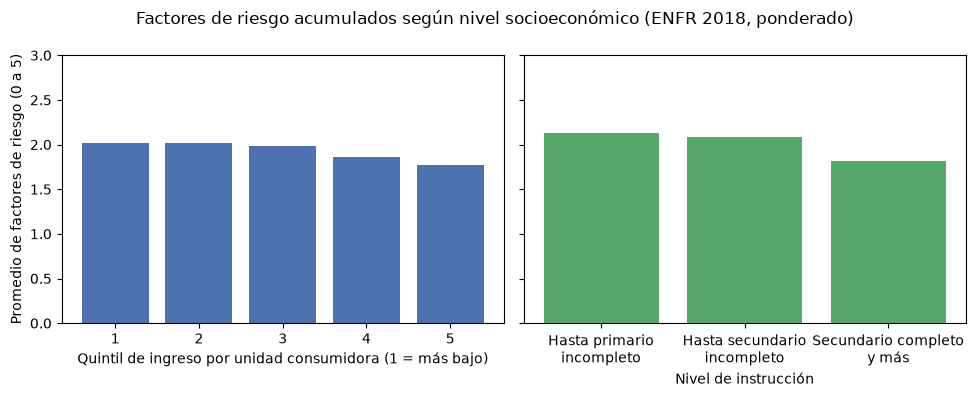

In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ejes[0].bar(tabla_quintil.index.astype(str), tabla_quintil["media_n_factores"], color="#4C72B0")
ejes[0].set_xlabel("Quintil de ingreso por unidad consumidora (1 = más bajo)")
ejes[0].set_ylabel("Promedio de factores de riesgo (0 a 5)")
etiquetas = ["Hasta primario\nincompleto", "Hasta secundario\nincompleto", "Secundario completo\ny más"]
ejes[1].bar(etiquetas, tabla_instr["media_n_factores"], color="#55A868")
ejes[1].set_xlabel("Nivel de instrucción")
for ax in ejes:
    ax.set_ylim(0, 3)
fig.suptitle("Factores de riesgo acumulados según nivel socioeconómico (ENFR 2018, ponderado)")
fig.tight_layout()
plt.show()

##### Graficos Extra
graficos extra que se pueden ver de este analisis.

Figure(800x400)
Figure(700x400)
Figure(1500x360)
Figure(1000x450)
Figure(900x400)
Figure(800x500)


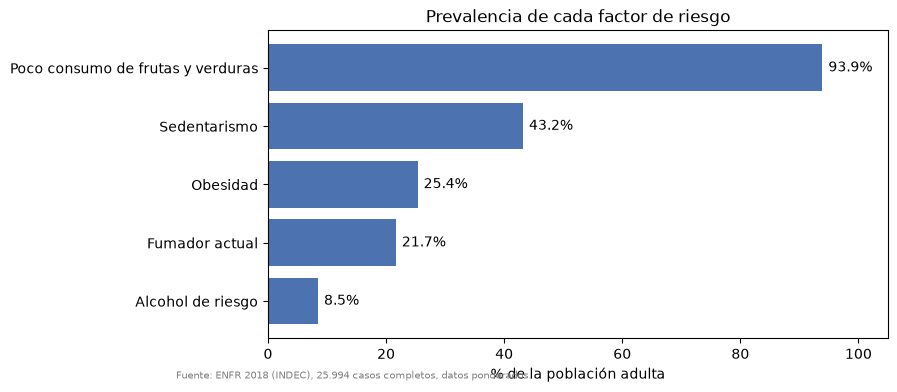

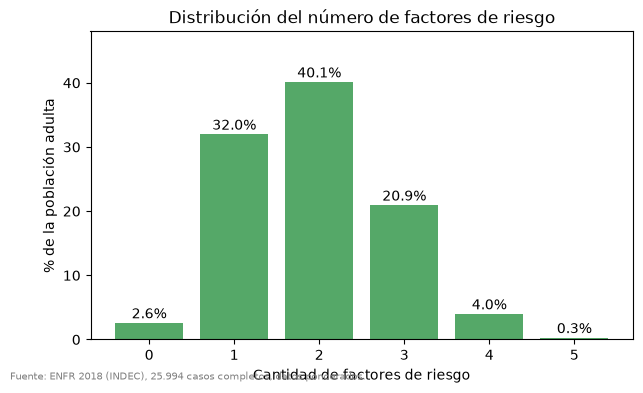

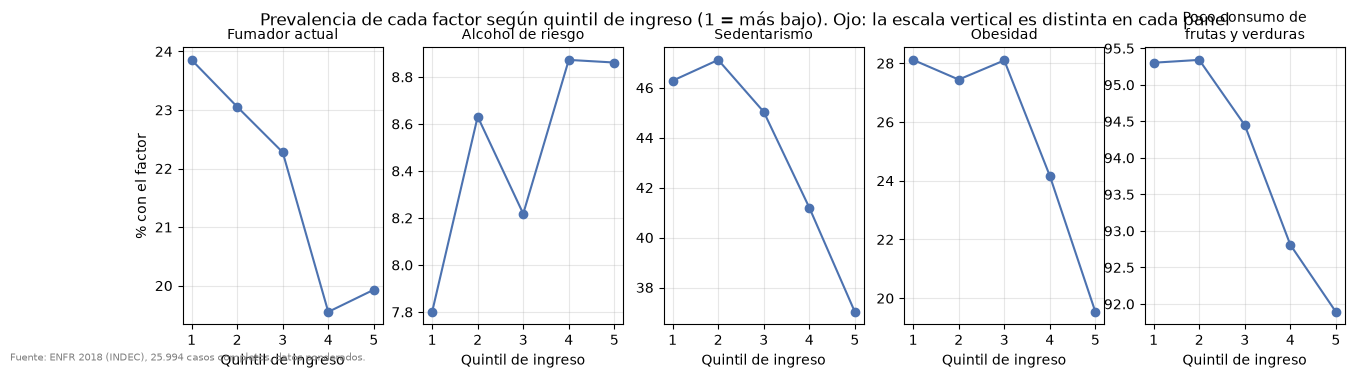

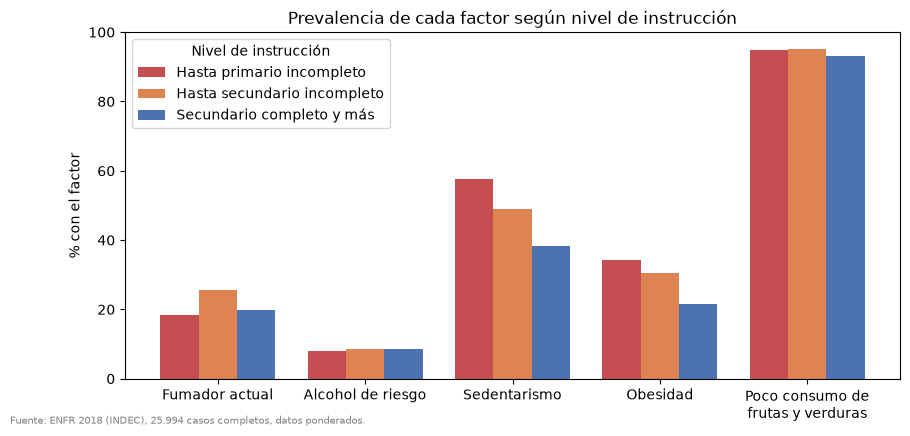

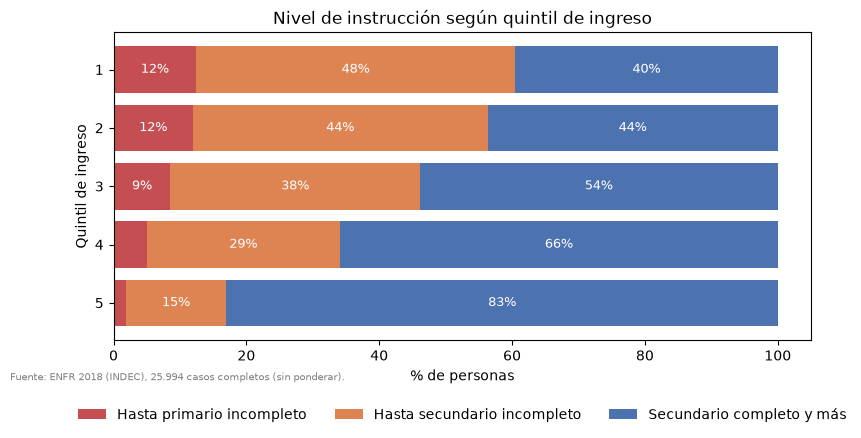

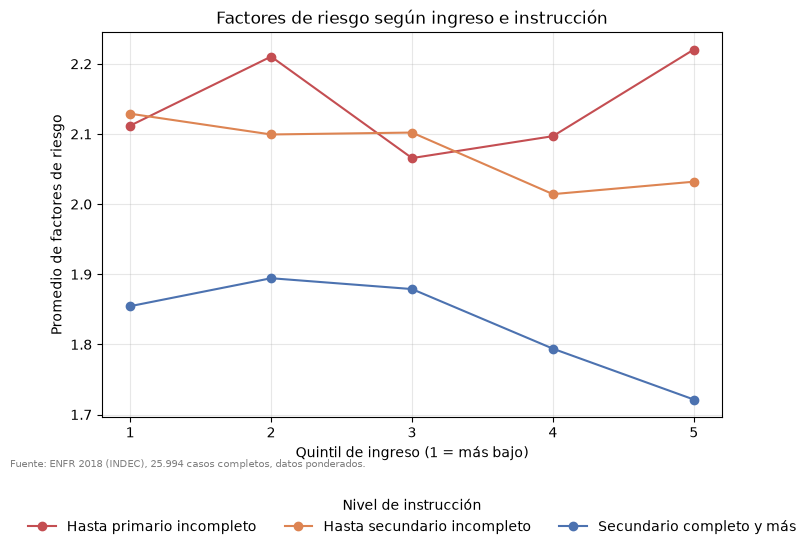

In [32]:
ETIQ = {"fuma": "Fumador actual", "alcohol_riesgo": "Alcohol de riesgo", "sedentarismo": "Sedentarismo",
        "obesidad": "Obesidad", "poco_fv": "Poco consumo de\nfrutas y verduras"}
ETIQ_INSTR = {1: "Hasta primario incompleto", 2: "Hasta secundario incompleto", 3: "Secundario completo y más"}
COLORES = {1: "#C44E52", 2: "#DD8452", 3: "#4C72B0"}
FUENTE = "Fuente: ENFR 2018 (INDEC), 25.994 casos completos, datos ponderados."
 
# 5.1 Prevalencia de cada factor
prev = pd.Series({f: 100 * media_pond(df_3C[f], w) for f in FACTORES}).sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh([ETIQ[f].replace("\n", " ") for f in prev.index], prev.values, color="#4C72B0")
for i, v in enumerate(prev.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center")
ax.set_xlim(0, 105)
ax.set_xlabel("% de la población adulta")
ax.set_title("Prevalencia de cada factor de riesgo")
fig.text(0.01, 0.01, FUENTE, fontsize=7, color="gray")
print(fig)
 
# 5.2 Distribución del número de factores
dist = [100 * w[(df_3C["n_factores"] == k).to_numpy()].sum() / w.sum() for k in range(6)]
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(6), dist, color="#55A868")
for k, v in enumerate(dist):
    ax.text(k, v + 0.7, f"{v:.1f}%", ha="center")
ax.set_xlabel("Cantidad de factores de riesgo")
ax.set_ylabel("% de la población adulta")
ax.set_ylim(0, 48)
ax.set_title("Distribución del número de factores de riesgo")
fig.text(0.01, 0.01, FUENTE, fontsize=7, color="gray")
print(fig)
 
# 5.3 Cada factor según quintil de ingreso
fig, ejes = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, f in zip(ejes, FACTORES):
    ax.plot(tabla_quintil.index, tabla_quintil[f], marker="o", color="#4C72B0")
    ax.set_title(ETIQ[f], fontsize=10)
    ax.set_xticks(range(1, 6))
    ax.set_xlabel("Quintil de ingreso")
    ax.grid(alpha=0.3)
ejes[0].set_ylabel("% con el factor")
fig.suptitle("Prevalencia de cada factor según quintil de ingreso (1 = más bajo). Ojo: la escala vertical es distinta en cada panel")
fig.text(0.01, 0.01, FUENTE, fontsize=7, color="gray")
print(fig)
 
# 5.4 Cada factor según nivel de instrucción
fig, ax = plt.subplots(figsize=(10, 4.5))
ancho = 0.26
for j, nivel in enumerate([1, 2, 3]):
    valores = [tabla_instr.loc[nivel, f] for f in FACTORES]
    ax.bar(np.arange(5) + (j - 1) * ancho, valores, ancho, label=ETIQ_INSTR[nivel], color=COLORES[nivel])
ax.set_xticks(range(5))
ax.set_xticklabels([ETIQ[f] for f in FACTORES])
ax.set_ylabel("% con el factor")
ax.set_ylim(0, 100)
ax.legend(title="Nivel de instrucción")
ax.set_title("Prevalencia de cada factor según nivel de instrucción")
fig.text(0.01, 0.01, FUENTE, fontsize=7, color="gray")
print(fig)
 
# 5.5 Instrucción según quintil de ingreso (apoya la correlación de Spearman)
cruce = pd.crosstab(df_3C["quintil_ingreso"], df_3C["instruccion"], normalize="index") * 100
fig, ax = plt.subplots(figsize=(9, 4))
izq = np.zeros(len(cruce))
for nivel in [1, 2, 3]:
    ax.barh(cruce.index.astype(str), cruce[nivel], left=izq, color=COLORES[nivel], label=ETIQ_INSTR[nivel])
    for i, v in enumerate(cruce[nivel]):
        if v > 6:
            ax.text(izq[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9)
    izq += cruce[nivel].to_numpy()
ax.set_ylabel("Quintil de ingreso")
ax.set_xlabel("% de personas")
ax.set_title("Nivel de instrucción según quintil de ingreso")
ax.invert_yaxis()
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
fig.text(0.01, 0.01, "Fuente: ENFR 2018 (INDEC), 25.994 casos completos (sin ponderar).", fontsize=7, color="gray")
print(fig)
 
# 5.6 Promedio de factores según quintil, separado por nivel de instrucción
fig, ax = plt.subplots(figsize=(8, 5))
for nivel in [1, 2, 3]:
    medias = [media_pond(g["n_factores"], g["peso_norm"])
              for _, g in df_3C[df_3C["instruccion"] == nivel].groupby("quintil_ingreso")]
    ax.plot(range(1, 6), medias, marker="o", label=ETIQ_INSTR[nivel], color=COLORES[nivel])
ax.set_xticks(range(1, 6))
ax.set_xlabel("Quintil de ingreso (1 = más bajo)")
ax.set_ylabel("Promedio de factores de riesgo")
ax.legend(title="Nivel de instrucción", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3, frameon=False)
ax.grid(alpha=0.3)
ax.set_title("Factores de riesgo según ingreso e instrucción")
fig.text(0.01, 0.01, FUENTE, fontsize=7, color="gray")
print(fig)


#### 6. Conclusión

La hipótesis se confirma **parcialmente**. Existe un gradiente socioeconómico en la acumulación de factores de riesgo: a mayor ingreso y a mayor nivel de instrucción, menos factores, y ambos efectos se mantienen cuando se controla por el otro y por sexo, edad y región. Sin embargo, ese gradiente se explica por tres factores (sedentarismo, obesidad y bajo consumo de frutas y verduras). El tabaquismo no muestra relación significativa con el ingreso una vez controlado el resto (solo con la instrucción) y el alcohol de riesgo no presenta gradiente alguno, lo que coincide con lo observado en el análisis bivariado inicial. El tamaño del efecto es moderado: la diferencia de ingreso entre el quintil 5 y el 1 equivale a unos 0,2 factores sobre un promedio de 1,9.

#### 7. Limitaciones

- La encuesta es transversal: muestra asociaciones, no causalidad (por ejemplo, la mala salud también puede reducir el ingreso).
- Sedentarismo, IMC y consumo de frutas y verduras son autorreportados.
- Un 94% de la población no llega a 5 porciones diarias de frutas y verduras, por lo que ese componente casi no discrimina y aporta poca variación al índice.
- Los resultados valen solo para la población adulta (18 años o más).